# Prédire les rendez-vous manqués dans les centres de santé
**Module :** Innovations technologiques en IA – L3 Ingénierie Informatique – UASZ

**Question :** parmi les patients suivis, lesquels risquent de manquer leur prochain rendez-vous ?

**Données :** *Medical Appointment No Shows* (Joni Hoppen, Kaggle, licence CC BY-NC-SA 4.0) – 110 527 rendez-vous médicaux au Brésil.
Ce sont de vraies données anonymisées, utilisées ici pour entraîner et évaluer le modèle. Le contexte n'est pas sénégalais, c'est une limite à signaler.

## 1. Chargement des données
On charge le fichier CSV avec pandas et on regarde sa taille et les premières lignes.

In [1]:
import pandas as pd

df = pd.read_csv("KaggleV2-May-2016.csv")

print(df.shape)  # (nombre de lignes, nombre de colonnes)
df.head()

(110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


## 2. Structure des données et variable à prédire
La colonne `No-show` indique si le patient est absent (`Yes`) ou présent (`No`). C'est elle qu'on veut prédire.
On regarde combien il y a d'absents : si la classe est très déséquilibrée, l'accuracy seule ne suffira pas pour évaluer le modèle.

In [2]:
df.info()  # types des colonnes et valeurs manquantes
print(df["No-show"].value_counts())
print(df["No-show"].value_counts(normalize=True))  # environ 80 % présents, 20 % absents

<class 'pandas.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  str    
 3   ScheduledDay    110527 non-null  str    
 4   AppointmentDay  110527 non-null  str    
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  str    
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  str    
dtypes: float64(1), int64(8), str(5)
memory usage: 17.6 MB
No-show
No     88208
Yes    22319
Name: count, dtype: int64
No-show
No     0.798067
Yes    0.201933
Name:

## 3. Nettoyage
- On convertit les dates, puis on calcule le **délai** (en jours) entre la prise du rendez-vous et le rendez-vous.
- On crée `absent` : 1 si le patient est absent, 0 s'il est présent.
- On enlève les valeurs impossibles : âge négatif, âge supérieur à 100 ans, délai négatif.

In [3]:
df["ScheduledDay"] = pd.to_datetime(df["ScheduledDay"])
df["AppointmentDay"] = pd.to_datetime(df["AppointmentDay"])

# délai entre la prise du rendez-vous et le jour du rendez-vous
df["delai"] = (df["AppointmentDay"].dt.normalize() - df["ScheduledDay"].dt.normalize()).dt.days

# variable à prédire : 1 = absent, 0 = présent
df["absent"] = (df["No-show"] == "Yes").astype(int)

# on garde seulement les valeurs possibles
df = df[(df["Age"] >= 0) & (df["Age"] <= 100)]
df = df[df["delai"] >= 0]

print(df.shape)  # environ 110 514 lignes

(110514, 16)


## 4. Premières observations
On regarde le taux d'absence selon le SMS reçu et selon le délai.
Les patients qui ont reçu un SMS manquent *plus* souvent leur rendez-vous. Ça ne veut pas dire que le SMS cause l'absence : les SMS sont surtout envoyés pour les rendez-vous lointains, qui sont déjà les plus manqués (corrélation, pas causalité).
C'est pourquoi on n'utilisera pas la variable `SMS_received` dans le modèle (voir partie 7).

In [4]:
print(df.groupby("SMS_received")["absent"].mean())
print(df.groupby(pd.cut(df["delai"], [-1, 0, 3, 7, 14, 30, 200]), observed=True)["absent"].mean())

SMS_received
0    0.166953
1    0.275753
Name: absent, dtype: float64
delai
(-1, 0]      0.046473
(0, 3]       0.228803
(3, 7]       0.252027
(7, 14]      0.304699
(14, 30]     0.325907
(30, 200]    0.329960
Name: absent, dtype: float64


## 5. Graphiques
Trois graphiques pour voir les tendances : le taux d'absence augmente avec le délai, il est plus élevé chez les 12-30 ans, et plus élevé chez les patients qui ont reçu un SMS (voir remarque ci-dessus).

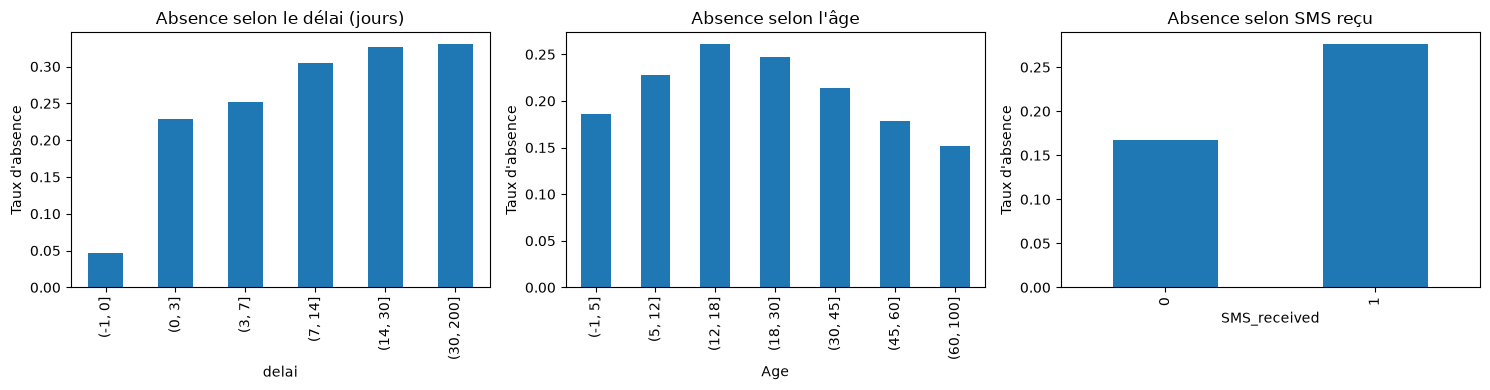

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df.groupby(pd.cut(df["delai"], [-1, 0, 3, 7, 14, 30, 200]), observed=True)["absent"].mean().plot(kind="bar", ax=axes[0], title="Absence selon le délai (jours)")
df.groupby(pd.cut(df["Age"], [-1, 5, 12, 18, 30, 45, 60, 100]), observed=True)["absent"].mean().plot(kind="bar", ax=axes[1], title="Absence selon l'âge")
df.groupby("SMS_received")["absent"].mean().plot(kind="bar", ax=axes[2], title="Absence selon SMS reçu")

for ax in axes:
    ax.set_ylabel("Taux d'absence")
plt.tight_layout()
plt.show()

## 6. Création de nouvelles colonnes
- `absences_passees` : nombre de rendez-vous déjà manqués par le patient *avant* le rendez-vous actuel. On trie par patient et par date, on cumule les absences, puis on retire le rendez-vous actuel pour ne pas tricher.
- `genre` et `handicap` : on les transforme en 0/1 pour que le modèle puisse les utiliser.

On voit que plus un patient a déjà manqué de rendez-vous, plus il risque de les manquer encore.

In [6]:
df = df.sort_values(["PatientId", "AppointmentDay"])

# absences passées du patient, sans compter le rendez-vous actuel
df["absences_passees"] = df.groupby("PatientId")["absent"].cumsum() - df["absent"]

df["genre"] = (df["Gender"] == "F").astype(int)
df["handicap"] = (df["Handcap"] > 0).astype(int)

print(df.groupby(df["absences_passees"].clip(upper=3))["absent"].mean())

absences_passees
0    0.186081
1    0.277854
2    0.311583
3    0.437105
Name: absent, dtype: float64


## 7. Choix des colonnes et séparation entraînement / test
On garde les colonnes utiles pour prédire (on enlève les identifiants et les quartiers brésiliens).
On retire aussi `SMS_received` : c'est la conséquence d'une décision du centre (envoyer ou non un rappel), pas une caractéristique du patient. Les SMS sont surtout envoyés pour les rendez-vous lointains, donc le modèle croirait à tort que le SMS augmente le risque d'absence.
Le modèle apprend sur 80 % des données et il est testé sur 20 % qu'il n'a jamais vues. `stratify=y` garde la même part d'absents (20 %) dans les deux groupes.

In [7]:
from sklearn.model_selection import train_test_split

colonnes = ["Age", "delai", "Scholarship", "Hipertension",
            "Diabetes", "Alcoholism", "handicap", "genre", "absences_passees"]

X = df[colonnes]  # informations connues avant le rendez-vous
y = df["absent"]  # ce qu'on veut prédire

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(88411, 9) (22103, 9)


## 8. Fonction d'évaluation et références
On définit une fonction qui entraîne un modèle puis affiche :
- **l'accuracy** : part de bonnes prédictions ;
- **la précision** : quand le modèle dit « absent », il a raison dans combien de cas ;
- **le rappel** : parmi les vrais absents, combien le modèle en retrouve ;
- **le F1** : un seul score qui combine précision et rappel (utile quand les classes sont déséquilibrées) ;
- **l'AUC** : capacité du modèle à classer les patients du moins risqué au plus risqué (0,5 = hasard, 1 = parfait) ;
- **la matrice de confusion** : ligne du haut = présents, ligne du bas = absents ; la case en haut à droite compte les fausses alertes, celle en bas à gauche les absents ratés.

On compare ensuite les modèles à deux références simples :
1. un modèle qui répond toujours « présent » : environ 80 % d'accuracy mais aucun absent détecté, donc l'accuracy seule ne suffit pas ici ;
2. une **règle simple** sur le délai (« si le rendez-vous est pris longtemps à l'avance, on prédit une absence »). Si un modèle ne fait pas mieux qu'une règle simple, le Machine Learning n'apporte pas grand-chose.

In [8]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.dummy import DummyClassifier

def evaluer(nom, modele):
    modele.fit(X_train, y_train)
    pred = modele.predict(X_test)
    print(nom)
    print("Accuracy  :", round(accuracy_score(y_test, pred), 3))
    print("Précision :", round(precision_score(y_test, pred, zero_division=0), 3))
    print("Rappel    :", round(recall_score(y_test, pred), 3))
    print("F1        :", round(f1_score(y_test, pred), 3))
    print("AUC       :", round(roc_auc_score(y_test, modele.predict_proba(X_test)[:, 1]), 3))
    print(confusion_matrix(y_test, pred))
    print()
    return modele

# référence 1 : répond toujours "présent"
evaluer("Référence 1 : modèle de base (dit toujours 'présent')", DummyClassifier(strategy="most_frequent"))

# référence 2 : règle simple sur le délai (le seuil est choisi sur le jeu d'entraînement)
seuil = max(range(1, 31), key=lambda s: f1_score(y_train, (X_train["delai"] >= s).astype(int)))
pred_regle = (X_test["delai"] >= seuil).astype(int)
print(f"Référence 2 : règle simple (délai >= {seuil} jours => absent)")
print("Accuracy  :", round(accuracy_score(y_test, pred_regle), 3))
print("Précision :", round(precision_score(y_test, pred_regle), 3))
print("Rappel    :", round(recall_score(y_test, pred_regle), 3))
print("F1        :", round(f1_score(y_test, pred_regle), 3))

Référence 1 : modèle de base (dit toujours 'présent')
Accuracy  : 0.798
Précision : 0.0
Rappel    : 0.0
F1        : 0.0
AUC       : 0.5
[[17641     0]
 [ 4462     0]]

Référence 2 : règle simple (délai >= 2 jours => absent)
Accuracy  : 0.545
Précision : 0.289
Rappel    : 0.86
F1        : 0.433


## 9. Régression logistique
Un modèle de classification simple. On en teste deux versions :
- la version simple, qui favorise les présents car ils sont beaucoup plus nombreux ;
- la version `class_weight="balanced"`, qui donne plus d'importance aux absents.

La version équilibrée a une accuracy plus faible mais retrouve beaucoup plus d'absents (rappel plus élevé). Pour envoyer des rappels par SMS, peu coûteux, c'est ce qui compte le plus.

In [9]:
from sklearn.linear_model import LogisticRegression

evaluer("Régression logistique simple", LogisticRegression(max_iter=1000))
evaluer("Régression logistique équilibrée", LogisticRegression(max_iter=1000, class_weight="balanced"))

Régression logistique simple
Accuracy  : 0.795
Précision : 0.425
Rappel    : 0.04
F1        : 0.073
AUC       : 0.668
[[17400   241]
 [ 4284   178]]

Régression logistique équilibrée
Accuracy  : 0.683
Précision : 0.327
Rappel    : 0.54
F1        : 0.407
AUC       : 0.674
[[12691  4950]
 [ 2054  2408]]



,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

## 10. Arbre de décision
Un arbre de décision de profondeur 5 (pour qu'il reste simple et ne retienne pas les données par cœur).
On affiche aussi l'importance de chaque variable : le **délai** pèse le plus dans la décision (environ 82 %), loin devant l'âge et les absences passées (environ 9 % chacun).

In [10]:
from sklearn.tree import DecisionTreeClassifier

arbre = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
evaluer("Arbre de décision", arbre)

importances = pd.Series(arbre.feature_importances_, index=colonnes).sort_values(ascending=False)
print(importances.round(3))

Arbre de décision
Accuracy  : 0.575
Précision : 0.301
Rappel    : 0.839
F1        : 0.443
AUC       : 0.728
[[8969 8672]
 [ 720 3742]]

delai               0.824
Age                 0.087
absences_passees    0.087
Alcoholism          0.001
Scholarship         0.001
genre               0.000
Hipertension        0.000
Diabetes            0.000
handicap            0.000
dtype: float64


## 11. Forêt aléatoire
Troisième algorithme : une forêt aléatoire combine plusieurs arbres de décision (ici 200) et fait voter leurs prédictions. Elle est en général plus stable qu'un arbre seul, mais plus difficile à expliquer.
On garde `class_weight="balanced"` pour tenir compte des absents, et on limite la profondeur pour éviter le surapprentissage.
Comme l'arbre, la forêt donne la première place au délai (environ 82 % de l'importance).

In [11]:
from sklearn.ensemble import RandomForestClassifier

foret = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=20,
                               class_weight="balanced", random_state=42, n_jobs=-1)
evaluer("Forêt aléatoire", foret)

importances_foret = pd.Series(foret.feature_importances_, index=colonnes).sort_values(ascending=False)
print(importances_foret.round(3))

Forêt aléatoire
Accuracy  : 0.575
Précision : 0.302
Rappel    : 0.845
F1        : 0.446
AUC       : 0.735
[[8943 8698]
 [ 690 3772]]

delai               0.817
absences_passees    0.081
Age                 0.079
Hipertension        0.007
genre               0.005
Scholarship         0.004
Alcoholism          0.003
handicap            0.002
Diabetes            0.002
dtype: float64


## 12. Comparaison et limites

| Modèle | Accuracy | Précision | Rappel | F1 | AUC |
|---|---|---|---|---|---|
| Référence 1 : toujours « présent » | 0.798 | 0 | 0 | 0 | 0.5 |
| Référence 2 : règle simple (délai ≥ 2 jours) | 0.545 | 0.289 | 0.860 | 0.433 | – |
| Régression logistique simple | 0.795 | 0.428 | 0.040 | 0.074 | 0.668 |
| Régression logistique équilibrée | 0.683 | 0.327 | 0.540 | 0.407 | 0.674 |
| Arbre de décision (profondeur 5) | 0.575 | 0.301 | 0.839 | 0.443 | 0.728 |
| Forêt aléatoire | 0.575 | 0.302 | 0.845 | 0.446 | 0.735 |

**Ce qu'on retient :**
- Prédire une absence est un problème difficile : tous les modèles restent modestes (F1 entre 0,41 et 0,45).
- Une règle simple sur le délai fait presque aussi bien (F1 0,433). Le délai est le signal principal : environ 82 % de l'importance dans l'arbre et dans la forêt. Le Machine Learning apporte surtout des niveaux de risque graduels (faible, moyen, élevé) et la prise en compte de l'âge et des absences passées.
- L'arbre et la forêt classent mieux les patients (AUC 0,73 à 0,74) que la régression logistique (0,67).
- Comme un rappel coûte peu, un rappel élevé est préférable à une précision élevée : on accepte des fausses alertes pour ne pas rater d'absents.

**Choix du modèle pour l'application :** la régression logistique équilibrée. Elle est facile à expliquer à un agent du centre et elle s'exporte sous forme de formule simple. En contrepartie, son AUC est plus faible : une amélioration possible serait d'utiliser la forêt, ou d'ajouter une variable « rendez-vous le jour même ».

**Limites :** données du Brésil (2016), pas du Sénégal ; peu de variables sur le patient (pas de distance, pas de type de consultation) ; un même patient peut apparaître dans l'entraînement et dans le test ; les modèles sont comparés sur un seul jeu de test (idéalement, on ajouterait un jeu de validation et la validation croisée) ; la corrélation observée n'est pas une cause (cas du SMS).

## 13. Probabilité d'absence pour chaque patient
Jusqu'ici, le modèle répondait seulement « absent » ou « présent ». Ici, on utilise `predict_proba` pour obtenir une **probabilité d'absence** (entre 0 et 1) pour chaque patient du jeu de test.
On garde aussi la vraie réponse (`absent`) pour pouvoir vérifier ensuite si le modèle avait raison.

In [12]:
modele = LogisticRegression(max_iter=1000, class_weight="balanced")
modele.fit(X_train, y_train)

# probabilité d'absence (entre 0 et 1) pour chaque patient du test
proba = modele.predict_proba(X_test)[:, 1]

resultat = X_test.copy()
resultat["proba"] = proba
resultat["absent"] = y_test  # la vraie réponse, pour vérifier
resultat.head()

,Age,delai,Scholarship,Hipertension,Diabetes,Alcoholism,handicap,genre,absences_passees,proba,absent
17736,22,2,0,0,0,0,0,1,0,0.414959,1
91159,5,12,0,0,0,0,0,0,0,0.521927,0
18548,7,0,0,0,0,0,0,0,0,0.416895,0
43689,42,0,0,0,0,0,0,1,0,0.364792,0
26572,16,4,0,0,0,0,0,1,0,0.442148,0


## 14. Niveaux de risque
On transforme la probabilité en trois niveaux pour que l'agent du centre comprenne facilement :
- **faible** : probabilité inférieure à 0.4 ;
- **moyen** : entre 0.4 et 0.6 ;
- **élevé** : supérieure à 0.6.

Pour vérifier que ces niveaux ont un sens, on regarde pour chaque niveau le taux réel d'absence. Si le modèle est utile, ce taux doit augmenter de « faible » à « élevé ».
Les seuils 0.4 et 0.6 sont un choix : on pourrait les changer selon le nombre de rappels que le centre peut envoyer.

In [13]:
# faible : proba < 0.4, moyen : de 0.4 à 0.6, élevé : > 0.6
resultat["niveau"] = pd.cut(resultat["proba"], [0, 0.4, 0.6, 1],
                            labels=["faible", "moyen", "élevé"], include_lowest=True)

# pour chaque niveau : nombre de patients et taux réel d'absence
print(resultat.groupby("niveau", observed=True)["absent"].agg(["count", "mean"]))

        count      mean
niveau                 
faible   7090  0.100282
moyen   11233  0.214724
élevé    3780  0.354233


### Lecture du résultat
Le taux d'absence augmente bien avec le niveau de risque : 10,0 % pour « faible », 21,5 % pour « moyen » et 35,4 % pour « élevé ».
Les patients « élevé » manquent donc leur rendez-vous environ 3,5 fois plus souvent que les « faible ». Le modèle aide à choisir qui relancer en priorité, mais il n'est pas parfait : environ 2 patients « élevé » sur 3 viennent quand même.

## 15. Export du modèle
On enregistre le modèle sous forme de formule (les poids de chaque variable et le point de départ) dans un fichier JSON. L'application web lit ce fichier pour calculer le risque d'un nouveau patient, sans refaire l'entraînement.

In [14]:
import json

with open("modele_absences.json", "w", encoding="utf-8") as f:
    json.dump({"colonnes": colonnes,
               "coef": modele.coef_[0].tolist(),
               "intercept": float(modele.intercept_[0])}, f, indent=2)
print("Modèle exporté")

Modèle exporté
